# Data exploration

The data of _Estrogen Receptr Status_ has already been splitted in two, 80% of it for trainning and the remain for testing the model. Here we aim to understand the dimensionality and characteristics of the data.


### Import functions

In [3]:
from sklearn.feature_selection import SelectPercentile, mutual_info_classif, f_classif
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import jaccard_score
from itertools import combinations
import matplotlib.pyplot as plt
from functools import partial
from pathlib import Path
import seaborn as sns
import joblib as jlb
import pandas as pd
import numpy as np
import os

# Locating to root directory
if "activities" in (cwd := Path.cwd()).parts or "src" in cwd.parts:
    folder = "activities" if "activities" in cwd.parts else "src"
    root = cwd.parents[len(cwd.parts) - 1 - cwd.parts.index(folder)]
    os.chdir(root)
    print(f"Working in: {Path.cwd()}")
else:
    print(f"Working in {cwd}")

Working in /home/pablosm/Escritorio/LCG/2027-1/DataScience/Machine_learning_algorithms_RE_state


## Exploring the data

It is clear that all files with labels corresponds to the target variable.

In [4]:
test_data = pd.read_csv("./data/EstrogenReceptorStatus_Test.csv", index_col=0)
test_labels = pd.read_csv(
    "./data/EstrogenReceptorStatus_Test_labels.txt", header=None
).squeeze("columns")
print(f"Test data shape: {test_data.shape}")
test_data.head(5)

Test data shape: (55, 162)


,1-hexadecanol,1-monostearin,"1,2,4-benzenetriol","1,5-anhydroglucitol","2-aminoadipic,acid","2-hydroxybutanoic,acid","2-hydroxyglutaric,acid","2-hydroxyvaleric,acid","2-ketoadipic,acid","2-ketoglucose,dimethylacetal,NIST",...,trehalose,tryptophan,tyrosine,uracil,urea,"uric,acid",uridine,uridine-5'-monophosphate,valine,xanthine
case_234,11.115704,10.066011,8.315212,13.787765,9.567422,13.792399,12.221783,12.723644,12.616868,11.655713,...,11.236411,13.989798,16.090678,14.345302,18.511690,11.356553,11.458261,9.241464,17.066334,9.263987
case_168,10.953540,9.455260,10.760813,14.134820,9.742248,14.143309,12.677246,14.918683,12.992772,6.090362,...,9.364537,14.230271,16.799025,16.225594,17.167450,13.052922,10.988278,7.981510,17.559720,8.708492
case_180,11.082995,9.501526,11.795980,14.150119,9.420807,14.074738,12.831977,15.620580,12.511738,6.167334,...,9.879903,14.344997,16.523343,16.457184,18.859713,13.664845,9.260993,7.076569,12.535361,9.607444
case_2,11.658437,10.598369,11.993399,12.298942,10.547373,14.436735,13.568694,16.712891,13.405477,7.022020,...,11.458791,13.027484,15.605371,14.627023,18.212003,12.266689,9.380577,7.969552,16.409022,8.477699
case_44,10.690867,9.868733,12.850994,13.205761,10.415339,13.977482,12.408161,15.354677,12.096834,6.907647,...,10.260879,13.072522,16.339286,15.566619,18.110454,11.890972,10.559301,6.574037,17.057968,10.040914


In [5]:
train_data = pd.read_csv("./data/EstrogenReceptorStatus_Train.csv", index_col=0)
train_labels = pd.read_csv(
    "./data/EstrogenReceptorStatus_Train_labels.txt", header=None
).squeeze("columns")
print(f"Train data shape: {train_data.shape}")
train_data.head(5)

Train data shape: (216, 162)


,1-hexadecanol,1-monostearin,"1,2,4-benzenetriol","1,5-anhydroglucitol","2-aminoadipic,acid","2-hydroxybutanoic,acid","2-hydroxyglutaric,acid","2-hydroxyvaleric,acid","2-ketoadipic,acid","2-ketoglucose,dimethylacetal,NIST",...,trehalose,tryptophan,tyrosine,uracil,urea,"uric,acid",uridine,uridine-5'-monophosphate,valine,xanthine
case_95,9.729131,9.372530,12.635429,14.711658,11.162607,14.145654,12.334462,14.358346,12.103635,5.686638,...,12.442494,14.244449,16.625366,15.192479,18.991252,13.594835,10.820097,7.306034,17.595868,11.431424
case_88,10.961073,9.353313,12.692373,14.371407,11.128662,14.228230,12.177452,14.923601,12.378531,6.527790,...,11.079405,14.744379,17.078661,14.517391,17.769687,12.833925,10.172577,8.658402,17.265167,8.184619
case_24,10.995057,9.384110,12.954097,13.323175,8.162313,14.392132,17.532062,16.000497,12.558596,6.235479,...,9.846626,13.916428,15.891040,15.440454,18.206261,13.260406,9.085237,6.846626,17.365810,8.544668
case_25,11.801188,10.131278,13.615486,13.612898,7.864104,14.637300,14.116084,12.750284,11.812189,7.284107,...,11.081869,11.704480,15.401228,15.387395,17.999114,12.303039,10.472097,8.118823,16.691485,10.108361
case_9,12.719130,11.215183,14.796994,13.753114,8.234385,14.321848,10.901360,11.932689,13.228521,7.088534,...,11.214305,13.858266,17.036357,17.610594,18.571197,12.947573,10.814716,7.404310,17.651466,11.811814


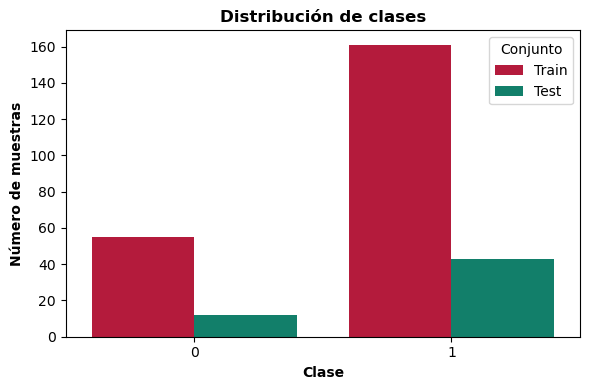

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))

sns.countplot(
    data=pd.DataFrame({
        "Clase": pd.concat([
            train_labels.astype(str),
            test_labels.astype(str)
        ], ignore_index=True),
        "Conjunto": (
            ["Train"] * len(train_labels) +
            ["Test"] * len(test_labels)
        )
    }),
    x="Clase",
    hue="Conjunto",
    order=["0", "1"],
    hue_order=["Train", "Test"],
    palette=["#CD022D", "#009175"],
    ax=ax
)

ax.set_xlabel("Clase", fontweight="bold")
ax.set_ylabel("Número de muestras", fontweight="bold")
ax.set_title("Distribución de clases", fontweight="bold")
ax.legend(title="Conjunto")

plt.tight_layout()
plt.show()

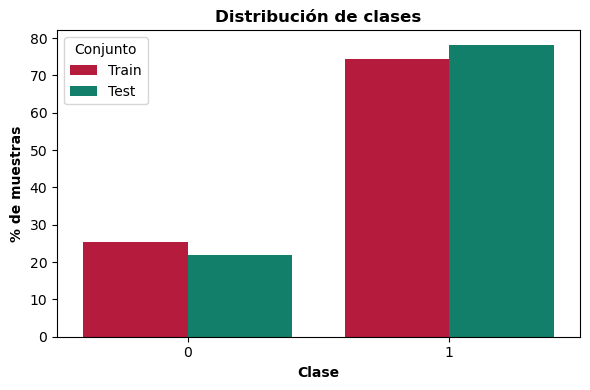

In [8]:
df_proportions = (
    pd.DataFrame({
        "Clase": pd.concat([
            train_labels.astype(str),
            test_labels.astype(str)
        ], ignore_index=True),
        "Conjunto": (
            ["Train"] * len(train_labels) +
            ["Test"] * len(test_labels)
        )
    })
    .groupby("Conjunto")["Clase"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Porcentaje")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(6, 4))

sns.barplot(
    data=df_proportions,
    x="Clase",
    y="Porcentaje",
    hue="Conjunto",
    order=["0", "1"],
    hue_order=["Train", "Test"],
    palette=["#CD022D", "#009175"],
    ax=ax
)

ax.set_xlabel("Clase", fontweight="bold")
ax.set_ylabel(r"% de muestras", fontweight="bold")
ax.set_title("Distribución de clases", fontweight="bold")
ax.legend(title="Conjunto")

del df_proportions, fig, ax

plt.tight_layout()
plt.show()

The plot reveals a clear **class inbalance** in both datasets, which must be considered for later processing. With the class 1 having the most of the data in it (>70% in both cases).

In [9]:
# Normalization of the data
scaler = StandardScaler()

train_scaled = pd.DataFrame(
    scaler.fit_transform(train_data),
    columns=train_data.columns,
    index=train_data.index
)

test_scaled = pd.DataFrame(
    scaler.transform(test_data),
    columns=test_data.columns,
    index=test_data.index
)

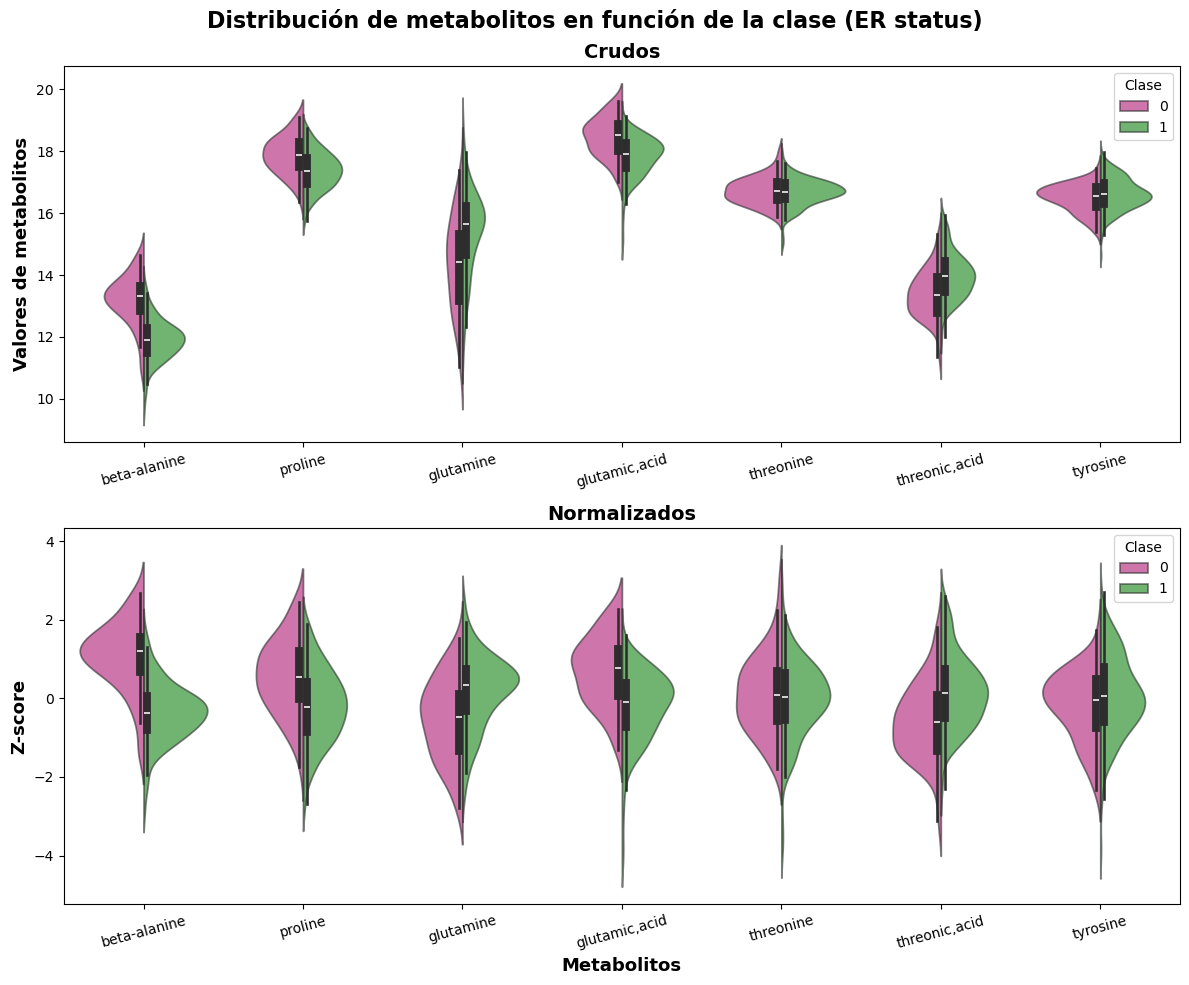

In [15]:
metabolites = [
    "beta-alanine",
    "proline",
    "glutamine",
    "glutamic,acid",
    "threonine",
    "threonic,acid",
    "tyrosine",
]

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

datasets = [
    (train_data, "Crudos", "Valores de metabolitos"),
    (train_scaled, "Normalizados", "Z-score")
]

for i, (ax, (dataset, title, ylabel)) in enumerate(zip(axes, datasets)):

    df = dataset[metabolites].copy()
    df["Class"] = train_labels.to_numpy().astype(str)

    sns.violinplot(
        data=df.melt(
            id_vars="Class",
            var_name="Metabolite",
            value_name="Value"
        ),
        x="Metabolite",
        y="Value",
        hue="Class",
        hue_order=["0", "1"],
        palette={"0": "#C7007C", "1": "#009503"},
        inner="box",
        ax=ax,
        alpha=0.6,
        split=True
    )

    ax.set_xlabel("Metabolitos" if i else "", fontsize=13, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=13, fontweight="bold")
    ax.set_title(title, fontsize=14, fontweight="bold")

    ax.tick_params(axis="x", rotation=15)
    ax.legend(title="Clase", loc="upper right")

fig.suptitle(
    "Distribución de metabolitos en función de la clase (ER status)",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

The exploratory analysis of metabolite distributions revealed differences between classes for certain metabolites, particularly β-alanine and glutamine. However, no consistent trend was observed in the direction of these differences, and the distributions showed considerable overlap. This suggests that the association between metabolic profiles and estrogen receptor status may depend on specific metabolites or multivariate patterns, rather than generalized changes in metabolite concentrations.

# Feature Selection

For both datasets, as it was expected, there are 162 characteristics or columns. Due to this great amount, it is relevant to reduce the complexity of the data. Here we only did withour transforming the data as dimensional reduction techniques wouldo, instead we choose to select the most informative features with the following methods:

- `f_classif`
- `mutual_info_classif`

`chi2` method was disscarded as we metabolomics data is continuos rather than discrete (non-negative integers), a must the method.

### Consensus analysis

Here we assessed which selected features were captured the most for a stochastic algorithm as MI within numerous data partitions.

In [19]:
cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=42)

methods = {
    "ANOVA": f_classif,
    # partial() enables "freezing" the random_state parameter for reproducibility
    "Información Mutua": partial(mutual_info_classif, random_state=42)
}

datasets = {
    "Sin normalización": train_data,
    "Con normalización": train_scaled
}

splits = list(cv.split(train_data, train_labels))

results = {}

for condition, dataset in datasets.items():

    results[condition] = {}

    for name, method in methods.items():
        masks = []

        for train_idx, _ in splits:
            selector = SelectPercentile(
                score_func=method,
                percentile=30
            )

            selector.fit(
                dataset.iloc[train_idx],
                train_labels.iloc[train_idx]
            )

            masks.append(selector.get_support())

        masks = np.array(masks)

        frequency = pd.Series(
            masks.mean(axis=0),
            index=dataset.columns,
            name="Frecuencia de selección"
        ).sort_values(ascending=False)

        jaccard = np.mean([
            jaccard_score(a, b)
            for a, b in combinations(masks, 2)
        ])

        results[condition][name] = {
            "frequency": frequency,
            "jaccard": jaccard
        }

        print(f"\n{condition} - {name}")
        print(f"Mean Jaccard: {jaccard:.3f}")
        print(frequency.head(10))


Sin normalización - ANOVA
Mean Jaccard: 0.735
2-hydroxyglutaric,acid    1.0
2-aminoadipic,acid        1.0
alanine                   1.0
3-phosphoglycerate        1.0
adenine                   1.0
uracil                    1.0
threonic,acid             1.0
malate                    1.0
idonic,acid,NIST          1.0
glycerol                  1.0
Name: Frecuencia de selección, dtype: float64

Sin normalización - Información Mutua
Mean Jaccard: 0.409
glutamic,acid             1.00
beta-alanine              1.00
idonic,acid,NIST          1.00
xanthine                  0.99
2-hydroxyglutaric,acid    0.99
uracil                    0.98
glucose                   0.98
oxalic,acid               0.97
proline                   0.91
dehydroascorbate          0.90
Name: Frecuencia de selección, dtype: float64

Con normalización - ANOVA
Mean Jaccard: 0.735
2-hydroxyglutaric,acid    1.0
2-aminoadipic,acid        1.0
alanine                   1.0
3-phosphoglycerate        1.0
adenine                  

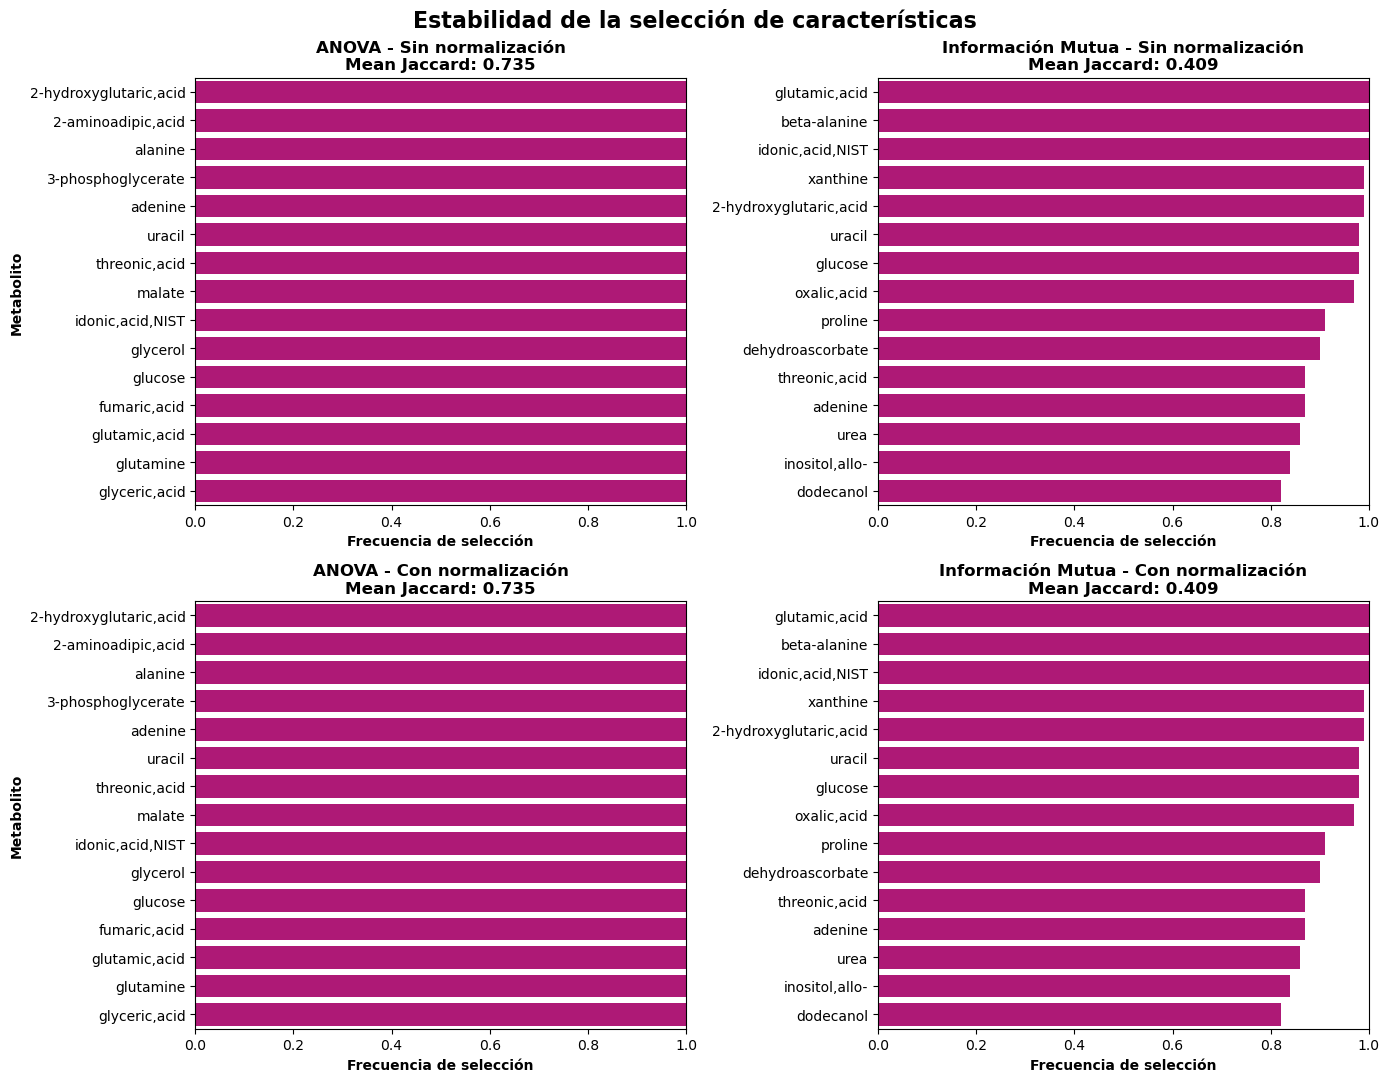

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for i, (condition, methods_results) in enumerate(results.items()):

    for j, (name, values) in enumerate(methods_results.items()):

        ax = axes[i, j]
        frequency = values["frequency"]
        jaccard = values["jaccard"]

        sns.barplot(
            x=frequency.head(15).values,
            y=frequency.head(15).index,
            color="#C7007C",
            ax=ax
        )

        ax.set_xlim(0, 1)
        ax.set_xlabel("Frecuencia de selección", fontweight="bold")
        ax.set_ylabel("Metabolito" if not j else "", fontweight="bold")

        ax.set_title(
            f"{name} - {condition}\nMean Jaccard: {jaccard:.3f}",
            fontweight="bold"
        )

fig.suptitle(
    "Estabilidad de la selección de características",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

There is no effect of normalization for the feature selection methods.

### Saving Feature Selection

With the aim of easing reproducibility, all objects of feature selected output are saved for its posterior usage.

In [11]:
methods = {
    "ANOVA": f_classif,
    "Mutual information": partial(mutual_info_classif, random_state=42)
}

output = Path("results/feature_selection")
output.mkdir(parents=True, exist_ok=True)

for name, method in methods.items():
    selector = SelectPercentile(
        score_func=method,
        percentile=20
    )
    selector.fit(train_data, train_labels)

    # Saving objects
    jlb.dump(
        selector,
        output / f"{name.lower().replace(' ', '_')}.joblib"
    )

    # Saving selected features
    for j, phase in enumerate(["Train", "Test"]):
        df = train_data if not j else test_data    
        df.loc[:, selector.get_feature_names_out()].to_csv(
            output / f"{name.lower().replace(' ', '_')}_{phase}.csv"
        )

    print(f"{name}: {selector.get_support().sum()} features selected")

ANOVA: 33 features selected
Mutual information: 33 features selected
